## WQD7003 Data Analytics Group Project

### **Title:**
### Prediction of Student Exam Scores Based on Academic, Demographic and Behavioral Factors

#### **Business Stakeholder:**
EdTech, a private tuition centre

#### **Business Goals:**

1. To gain insights into the main factors that affect student performance.
2. To identify at-risk student profiles for timely and individualised academic interventions.
3. To increase the proportion of students achieving above-average exam scores.


#### **Data Mining Goals:**

1. To identify the most influential factors affecting student academic performance.
2. To develop a predictive model to estimate student exam scores.
3. To provide personalised recommendations based on prediction scores.


### Table of Contents
1. [Data Understanding](#1-data-understanding)
   - 1.1 Gathering and Describing Data
   - 1.2 Early Data Exploration and Quality Check
2. [Data Preparation](#2-data-preparation)
   - 2.1 Missing Value Imputation
   - 2.2 Outlier Detection and Handling
3. [Exploratory Data Analysis (EDA)](#3-exploratory-data-analysis-eda)
   - 3.1 Normality Tests
   - 3.2 Correlation Analysis
   - 3.3 Categorical Variable Analysis
   - 3.4 Statistical Tests
4. [Data Modeling](#4-data-modeling)
   - 4.1 Data Preparation for Modeling
   - 4.2 Baseline Models
   - 4.3 Cross Validation Model Evaluation and Comparison
   - 4.4 Hyperparameter Tuning of all models
   - 4.5 Complete Model Comparison
   - 4.6 Best Model Selection
5. [Conclusions and Recommendations](#5-conclusions-and-recommendations)

# 1. Data Understanding

In this section, we load the dataset and perform initial exploration to understand its structure, data types, and quality.

In [ ]:
# Import all required packages
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy.stats import mannwhitneyu, kruskal
from IPython.display import display, HTML
from scipy.stats import spearmanr

# Machine Learning packages
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, learning_curve
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# Configuration
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

print("All packages imported successfully!")

All packages imported successfully!


### 1.1 Gathering and Describing Data

Load the dataset and examine its structure.

In [ ]:
# Read the dataset
df = pd.read_csv('StudentPerformanceFactors.csv')

# Display basic information
print(f"Dataset Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"\nMemory Usage: {df.memory_usage(deep=True).sum() / 1024:.2f} KB")
df.head(10)

Dataset Shape: 6,607 rows × 20 columns

Memory Usage: 4887.49 KB


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
5,19,88,Medium,Medium,Yes,8,89,Medium,Yes,3,Medium,Medium,Public,Positive,3,No,Postgraduate,Near,Male,71
6,29,84,Medium,Low,Yes,7,68,Low,Yes,1,Low,Medium,Private,Neutral,2,No,High School,Moderate,Male,67
7,25,78,Low,High,Yes,6,50,Medium,Yes,1,High,High,Public,Negative,2,No,High School,Far,Male,66
8,17,94,Medium,High,No,6,80,High,Yes,0,Medium,Low,Private,Neutral,1,No,College,Near,Male,69
9,23,98,Medium,Medium,Yes,8,71,Medium,Yes,0,High,High,Public,Positive,5,No,High School,Moderate,Male,72


In [ ]:
# Detailed column information

print("\n--- Column Description ---")


# Separate numerical and categorical columns
numerical_cols = df.select_dtypes(include=['number']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print(f"\nNumerical Columns ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical Columns ({len(categorical_cols)}): {categorical_cols}")

# Data types and sample values
print("\n" + "-" * 80)
for col in df.columns:
    dtype = df[col].dtype
    n_unique = df[col].nunique()
    sample = df[col].dropna().head(3).tolist()
    print(f"{col:<30} | Type: {str(dtype):<10} | Unique: {n_unique:<5} | Sample: {sample}")


--- Column Description ---

Numerical Columns (7): ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score']
Categorical Columns (13): ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

--------------------------------------------------------------------------------
Hours_Studied                  | Type: int64      | Unique: 41    | Sample: [23, 19, 24]
Attendance                     | Type: int64      | Unique: 41    | Sample: [84, 64, 98]
Parental_Involvement           | Type: object     | Unique: 3     | Sample: ['Low', 'Low', 'Medium']
Access_to_Resources            | Type: object     | Unique: 3     | Sample: ['High', 'Medium', 'Medium']
Extracurricular_Activities     | Type: object     | Unique: 2  

### 1.2 Early Data Exploration and Quality Check

#### 1.2.1 Numerical Variables Analysis

In [ ]:
# Statistical summary for numerical columns
print("Descriptive Statistics for Numerical Variables")
print("-" * 80)
df[numerical_cols].describe().round(2)

Descriptive Statistics for Numerical Variables
--------------------------------------------------------------------------------


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.00,6607.00,6607.00,6607.00,6607.00,6607.00,6607.00
mean,19.98,79.98,7.03,75.07,1.49,2.97,67.24
std,5.99,11.55,1.47,14.40,1.23,1.03,3.89
min,1.00,60.00,4.00,50.00,0.00,0.00,55.00
25%,16.00,70.00,6.00,63.00,1.00,2.00,65.00
50%,20.00,80.00,7.00,75.00,1.00,3.00,67.00
75%,24.00,90.00,8.00,88.00,2.00,4.00,69.00
max,44.00,100.00,10.00,100.00,8.00,6.00,101.00


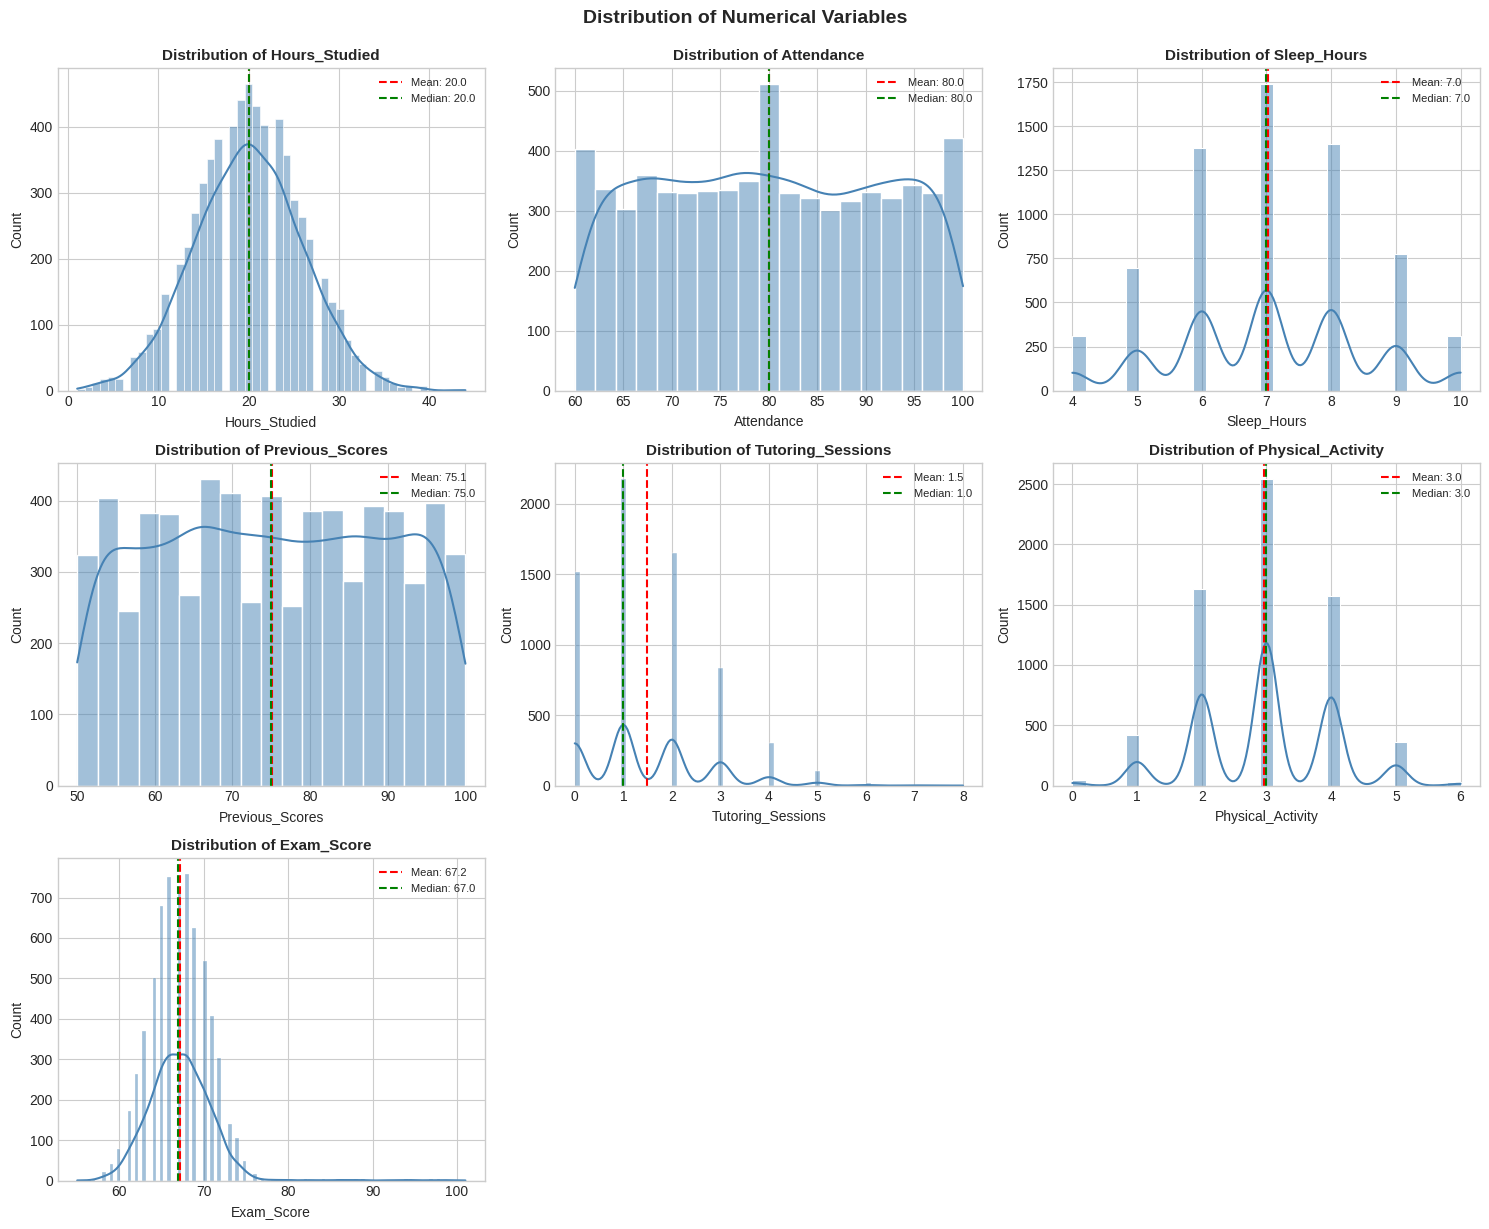

In [ ]:
# Distribution plots for numerical variables
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for idx, col in enumerate(numerical_cols):
    if idx < len(axes):
        ax = axes[idx]
        sns.histplot(df[col], kde=True, color='steelblue', ax=ax, edgecolor='white')
        ax.axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean: {df[col].mean():.1f}')
        ax.axvline(df[col].median(), color='green', linestyle='--', label=f'Median: {df[col].median():.1f}')
        ax.set_title(f'Distribution of {col}', fontsize=11, fontweight='bold')
        ax.legend(fontsize=8)

# Hide empty subplots
for idx in range(len(numerical_cols), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.suptitle('Distribution of Numerical Variables', y=1.02, fontsize=14, fontweight='bold')
plt.show()

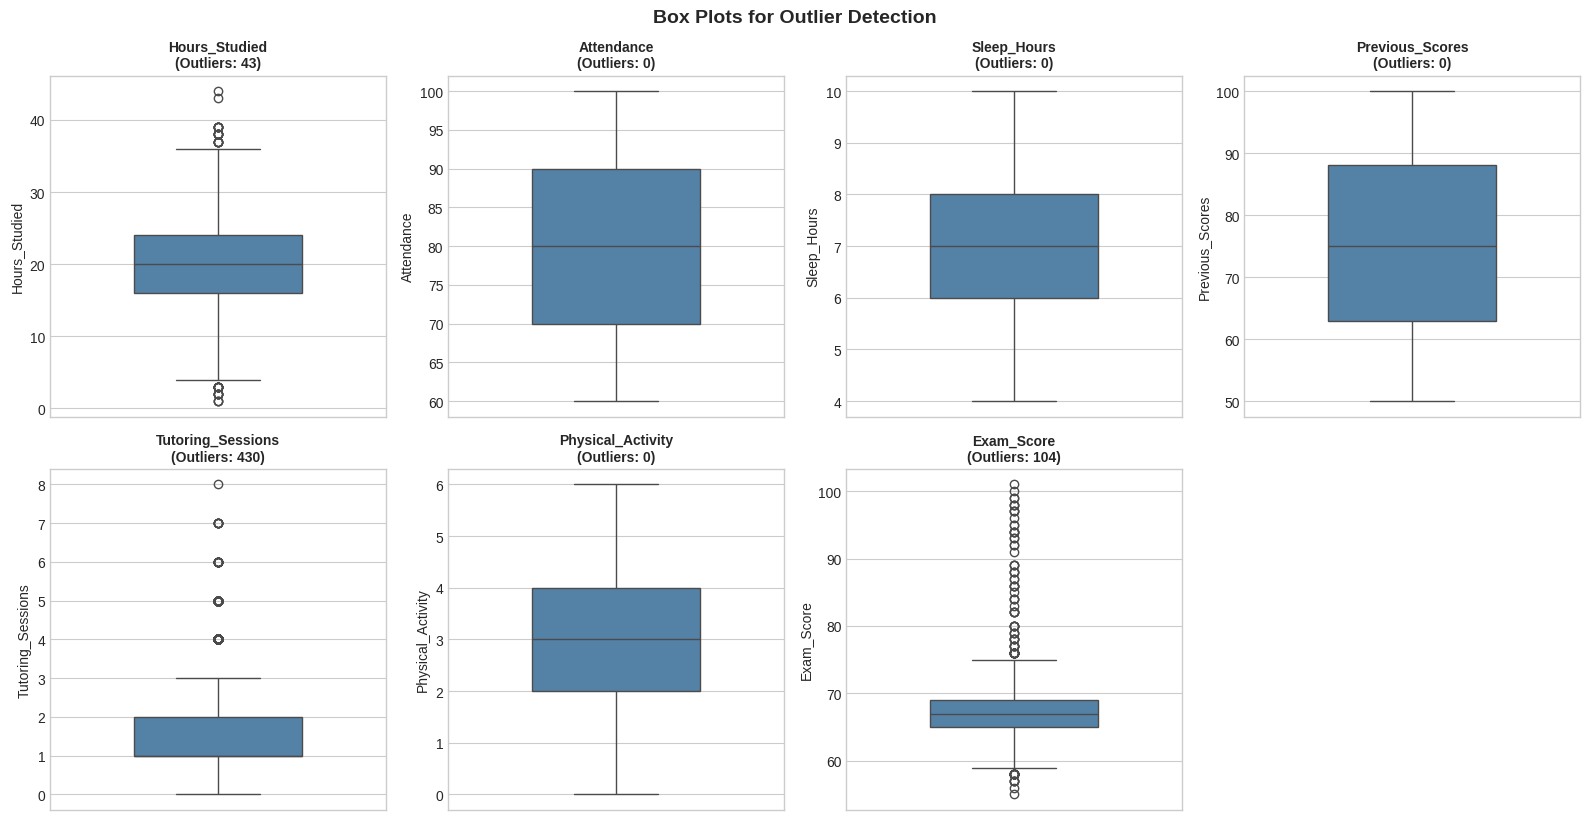

In [ ]:
# Box plots to identify outliers
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, col in enumerate(numerical_cols):
    if idx < len(axes):
        ax = axes[idx]
        box = sns.boxplot(y=df[col], color='steelblue', ax=ax, width=0.5)

        # Calculate and display outlier count
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        outliers = df[(df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)][col]
        ax.set_title(f'{col}\n(Outliers: {len(outliers)})', fontsize=10, fontweight='bold')

for idx in range(len(numerical_cols), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.suptitle('Box Plots for Outlier Detection', y=1.02, fontsize=14, fontweight='bold')
plt.show()

#### 1.2.2 Categorical Variables Analysis

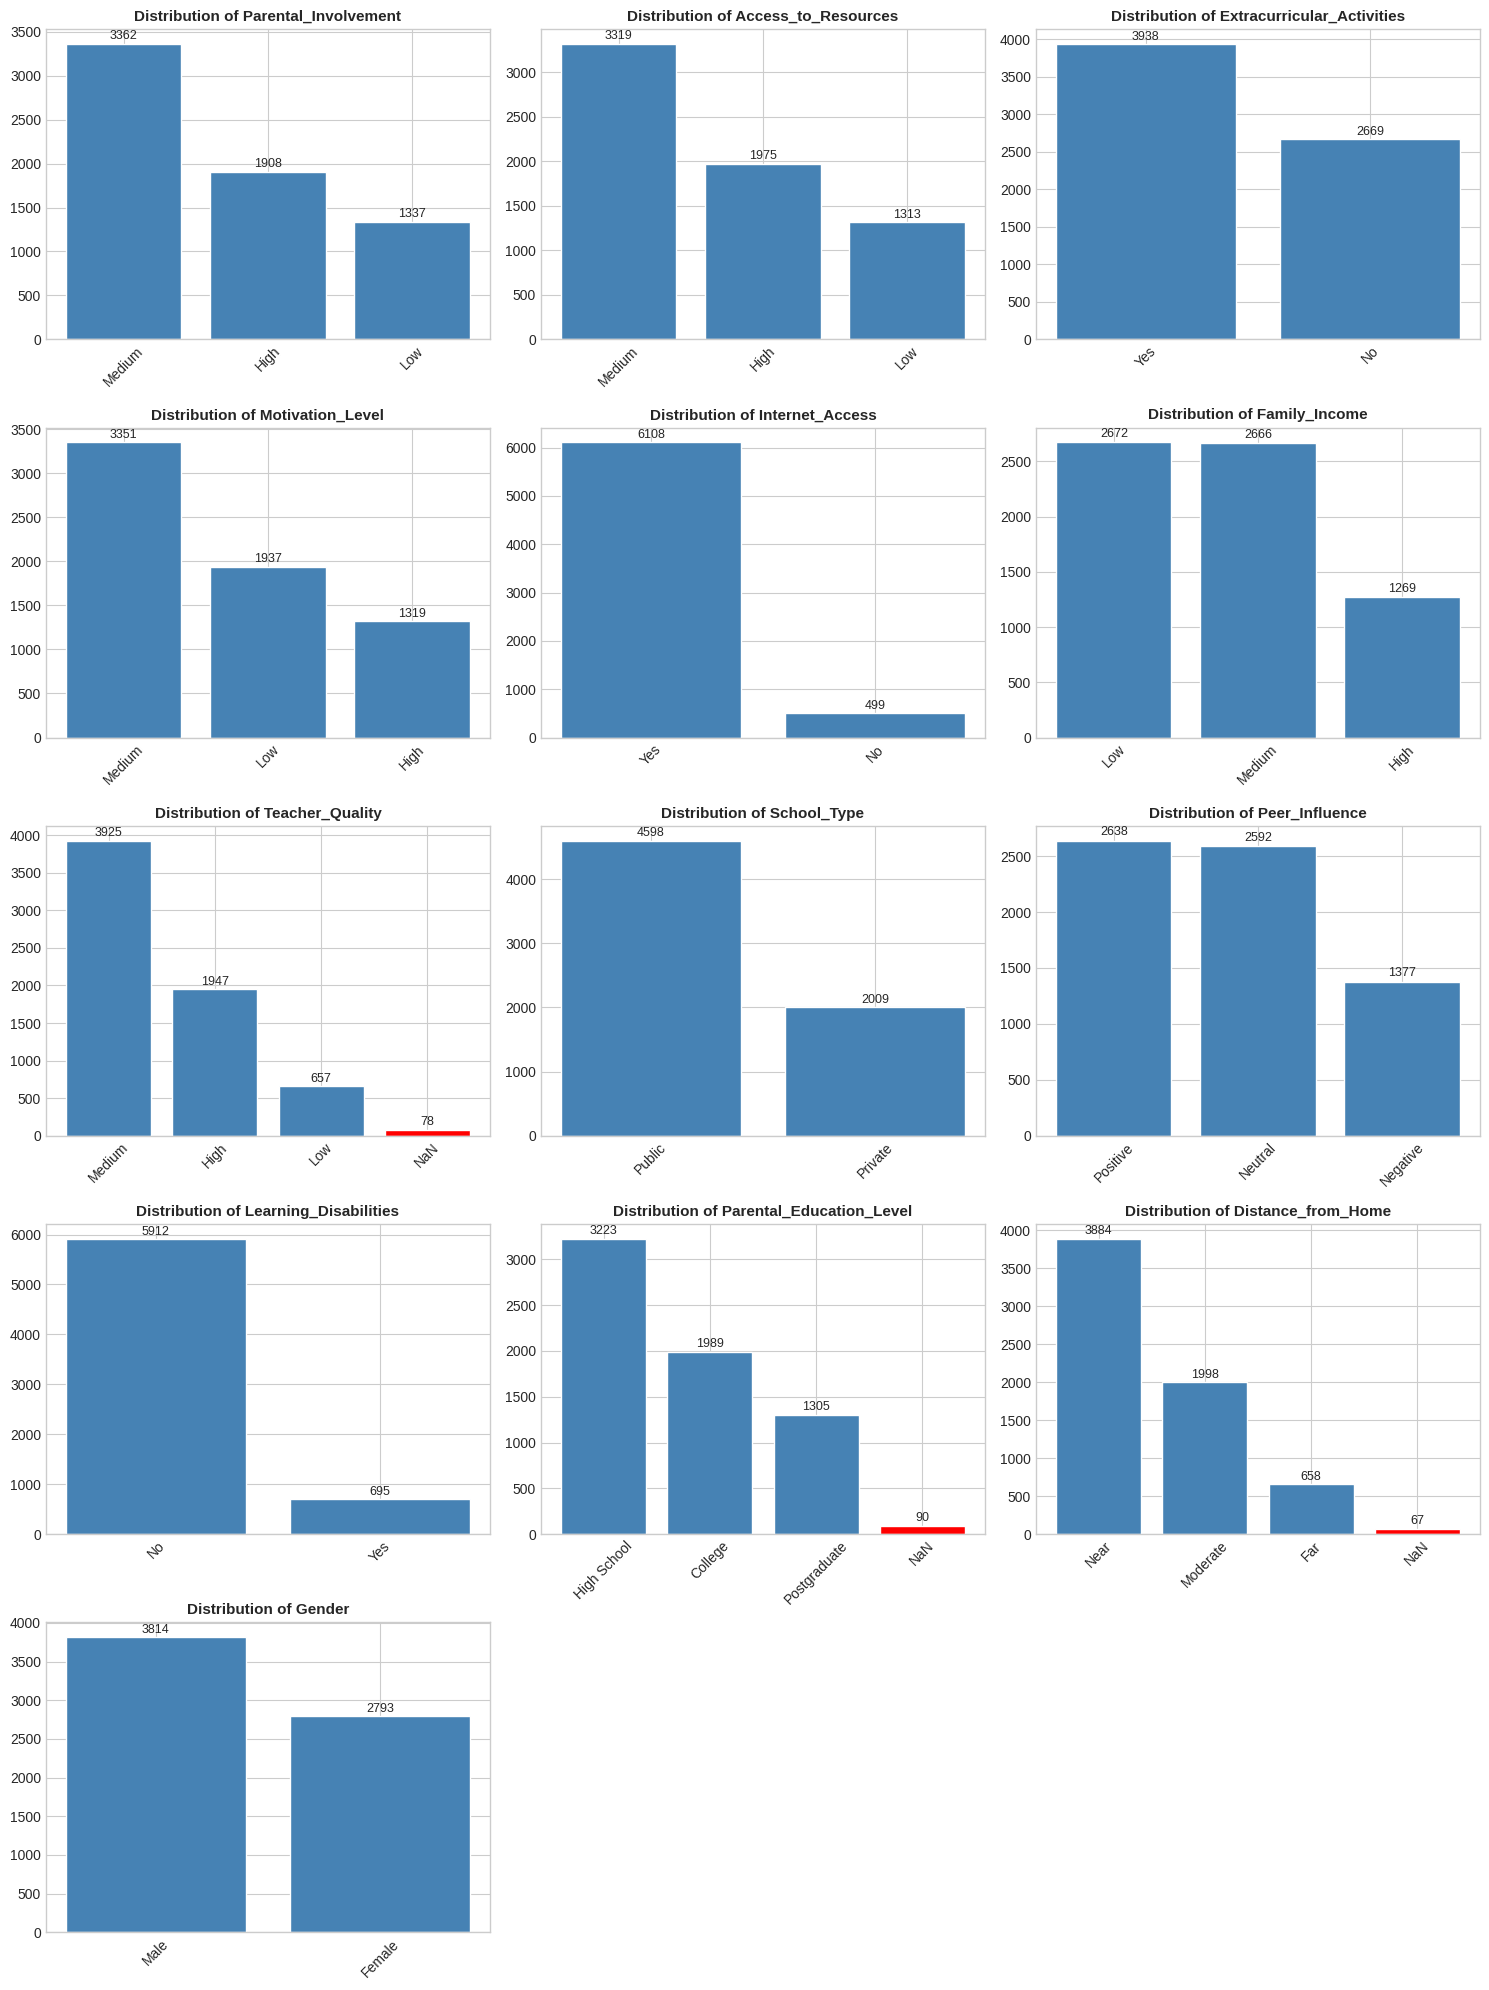

In [ ]:
# Distribution of categorical variables
n_cat = len(categorical_cols)
n_rows = (n_cat + 2) // 3
fig, axes = plt.subplots(n_rows, 3, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for idx, col in enumerate(categorical_cols):
    ax = axes[idx]
    # Fill NaN values with 'NaN' category for visualization
    value_counts = df[col].fillna('NaN').value_counts()

    # Define colors for bars: red for 'NaN', steelblue for others
    bar_colors = ['red' if cat == 'NaN' else 'steelblue' for cat in value_counts.index]

    bars = ax.bar(value_counts.index, value_counts.values, color=bar_colors, edgecolor='white')

    ax.set_title(f'Distribution of {col}', fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)

    # Add value labels on bars
    for bar, val in zip(bars, value_counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                f'{val}', ha='center', va='bottom', fontsize=9)

for idx in range(len(categorical_cols), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

#### 1.2.3 Missing Value Analysis

Columns with Missing Values:
------------------------------------------------------------


,Missing Count,Missing %,Data Type
Parental_Education_Level,90,1.36,object
Teacher_Quality,78,1.18,object
Distance_from_Home,67,1.01,object


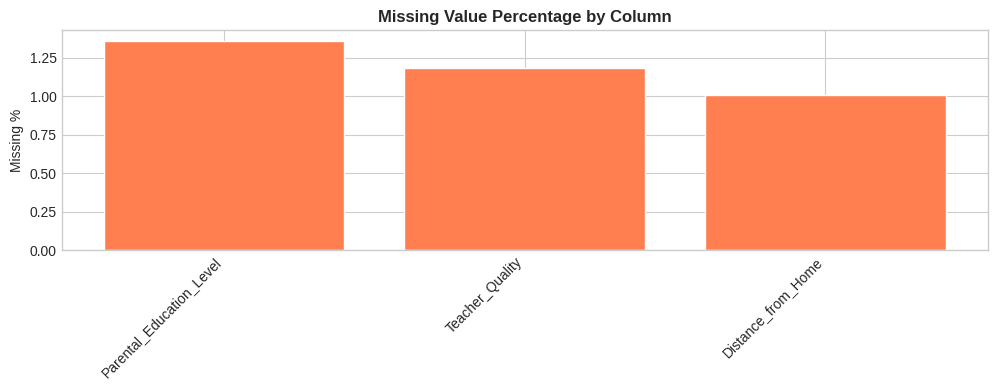

In [ ]:
# Missing value analysis
missing_count = df.isna().sum()
missing_percent = (df.isna().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing %': missing_percent,
    'Data Type': df.dtypes
}).sort_values('Missing %', ascending=False)

# Filter to show only columns with missing values
missing_only = missing_summary[missing_summary['Missing Count'] > 0]

if len(missing_only) > 0:
    print("Columns with Missing Values:")
    print("-" * 60)
    display(missing_only)

    # Visualize missing values
    plt.figure(figsize=(10, 4))
    plt.bar(missing_only.index, missing_only['Missing %'], color='coral', edgecolor='white')
    plt.title('Missing Value Percentage by Column', fontsize=12, fontweight='bold')
    plt.ylabel('Missing %')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the dataset!")

# 2. Data Preparation

In this section, we handle missing values using iterative imputation and address any data quality issues.

## 2.1 Missing Value Imputation

We use IterativeImputer (MICE - Multivariate Imputation by Chained Equations) for sophisticated missing value handling.

In [ ]:
# Create a copy for imputation
df_imputed = df.copy()

# Identify columns with missing values
missing_cols = df_imputed.columns[df_imputed.isnull().any()].tolist()

if not missing_cols:
    print("No missing values found. Imputation skipped.")
else:
    print(f"Columns requiring imputation: {missing_cols}")

    # Separate columns for imputation
    df_to_impute = df_imputed[missing_cols].copy()

    # Identify categorical and numerical columns within those needing imputation
    categorical_cols_to_impute = df_to_impute.select_dtypes(include='object').columns.tolist()
    numerical_cols_to_impute = df_to_impute.select_dtypes(include=['number']).columns.tolist()

    print(f"  - Categorical columns to impute: {categorical_cols_to_impute}")
    print(f"  - Numerical columns to impute: {numerical_cols_to_impute}")

    # Store OrdinalEncoders for inverse transformation
    ordinal_encoders = {}
    for col in categorical_cols_to_impute:
        oe = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
        df_to_impute[col] = oe.fit_transform(df_to_impute[[col]])
        ordinal_encoders[col] = oe

    # Apply IterativeImputer
    imputer = IterativeImputer(random_state=RANDOM_STATE, max_iter=10)
    imputed_data = imputer.fit_transform(df_to_impute)

    # Convert back to DataFrame
    df_imputed_processed = pd.DataFrame(imputed_data, columns=df_to_impute.columns, index=df_to_impute.index)

    # Inverse transform categorical columns
    for col in categorical_cols_to_impute:
        n_categories = len(ordinal_encoders[col].categories_[0])
        df_imputed_processed[col] = df_imputed_processed[col].round().clip(0, n_categories - 1).astype(int)
        df_imputed_processed[col] = ordinal_encoders[col].inverse_transform(df_imputed_processed[[col]]).flatten()

    # Update the main DataFrame
    df_imputed[missing_cols] = df_imputed_processed[missing_cols]

    # Verify imputation
    remaining_missing = df_imputed.isna().sum().sum()
    print(f"\nImputation complete! Remaining missing values: {remaining_missing}")

Columns requiring imputation: ['Teacher_Quality', 'Parental_Education_Level', 'Distance_from_Home']
  - Categorical columns to impute: ['Teacher_Quality', 'Parental_Education_Level', 'Distance_from_Home']
  - Numerical columns to impute: []

Imputation complete! Remaining missing values: 0


## 2.2 Outlier Detection Summary

While outliers exist in some variables, we retain them as they represent valid student behaviors (e.g., students who study many hours or have perfect attendance).

In [ ]:
# Outlier detection summary using IQR method
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower) | (data[column] > upper)]
    return len(outliers), lower, upper

outlier_summary = []
for col in df_imputed.select_dtypes(include=['number']).columns:
    count, lower, upper = detect_outliers_iqr(df_imputed, col)
    outlier_summary.append({
        'Variable': col,
        'Outlier Count': count,
        'Outlier %': round(count / len(df_imputed) * 100, 2),
        'Lower Bound': round(lower, 2),
        'Upper Bound': round(upper, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
print("Outlier Summary (IQR Method):")
display(outlier_df)

Outlier Summary (IQR Method):


,Variable,Outlier Count,Outlier %,Lower Bound,Upper Bound
0,Hours_Studied,43,0.65,4.0,36.0
1,Attendance,0,0.00,40.0,120.0
2,Sleep_Hours,0,0.00,3.0,11.0
3,Previous_Scores,0,0.00,25.5,125.5
4,Tutoring_Sessions,430,6.51,-0.5,3.5
5,Physical_Activity,0,0.00,-1.0,7.0
6,Exam_Score,104,1.57,59.0,75.0


In [ ]:
# Display cleaned data sample
print("\nCleaned Dataset Preview:")
df_imputed.head(10)


Cleaned Dataset Preview:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
5,19,88,Medium,Medium,Yes,8,89,Medium,Yes,3,Medium,Medium,Public,Positive,3,No,Postgraduate,Near,Male,71
6,29,84,Medium,Low,Yes,7,68,Low,Yes,1,Low,Medium,Private,Neutral,2,No,High School,Moderate,Male,67
7,25,78,Low,High,Yes,6,50,Medium,Yes,1,High,High,Public,Negative,2,No,High School,Far,Male,66
8,17,94,Medium,High,No,6,80,High,Yes,0,Medium,Low,Private,Neutral,1,No,College,Near,Male,69
9,23,98,Medium,Medium,Yes,8,71,Medium,Yes,0,High,High,Public,Positive,5,No,High School,Moderate,Male,72


# 3. Exploratory Data Analysis (EDA)

In this section, we analyze relationships between features and the target variable (Exam_Score).

## 3.1 Normality Tests

Testing whether numerical variables follow a normal distribution.

In [ ]:
# Normality tests
num_cols = df_imputed.select_dtypes(include=["number"]).columns.tolist()
normality_results = []

for col in num_cols:
    data = df_imputed[col].dropna()
    n = len(data)
    if n < 3:
        continue

    # Sample for Shapiro-Wilk if n > 5000
    sample = data.sample(min(5000, n), random_state=RANDOM_STATE) if n > 5000 else data
    shapiro_W, shapiro_p = stats.shapiro(sample)

    # Kolmogorov-Smirnov test
    if data.std() > 0:
        standardized = (data - data.mean()) / data.std(ddof=0)
        ks_D, ks_p = stats.kstest(standardized, "norm")
    else:
        ks_D, ks_p = np.nan, np.nan

    normality_results.append({
        "Variable": col,
        "N": n,
        "Shapiro-W": round(shapiro_W, 4),
        "Shapiro p-value": f"{shapiro_p:.2e}" if shapiro_p < 0.001 else round(shapiro_p, 4),
        "K-S D": round(ks_D, 4) if not np.isnan(ks_D) else "N/A",
        "K-S p-value": f"{ks_p:.2e}" if ks_p < 0.001 else round(ks_p, 4) if not np.isnan(ks_p) else "N/A",
        "Normal?": "Yes" if shapiro_p > 0.05 else "No"
    })

normality_df = pd.DataFrame(normality_results)
print("Normality Test Results (α = 0.05):")
display(normality_df)

Normality Test Results (α = 0.05):


,Variable,N,Shapiro-W,Shapiro p-value,K-S D,K-S p-value,Normal?
0,Hours_Studied,6607,0.9973,8.73e-08,0.0361,6.73e-08,No
1,Attendance,6607,0.9547,8.20e-37,0.0716,7.11e-30,No
2,Sleep_Hours,6607,0.9529,2.19e-37,0.1319,1.17e-100,No
3,Previous_Scores,6607,0.9564,2.92e-36,0.0682,3.42e-27,No
4,Tutoring_Sessions,6607,0.8880,3.91e-51,0.2147,9.63e-268,No
5,Physical_Activity,6607,0.9211,2.68e-45,0.1956,6.32e-222,No
6,Exam_Score,6607,0.9182,6.93e-46,0.0817,7.88e-39,No


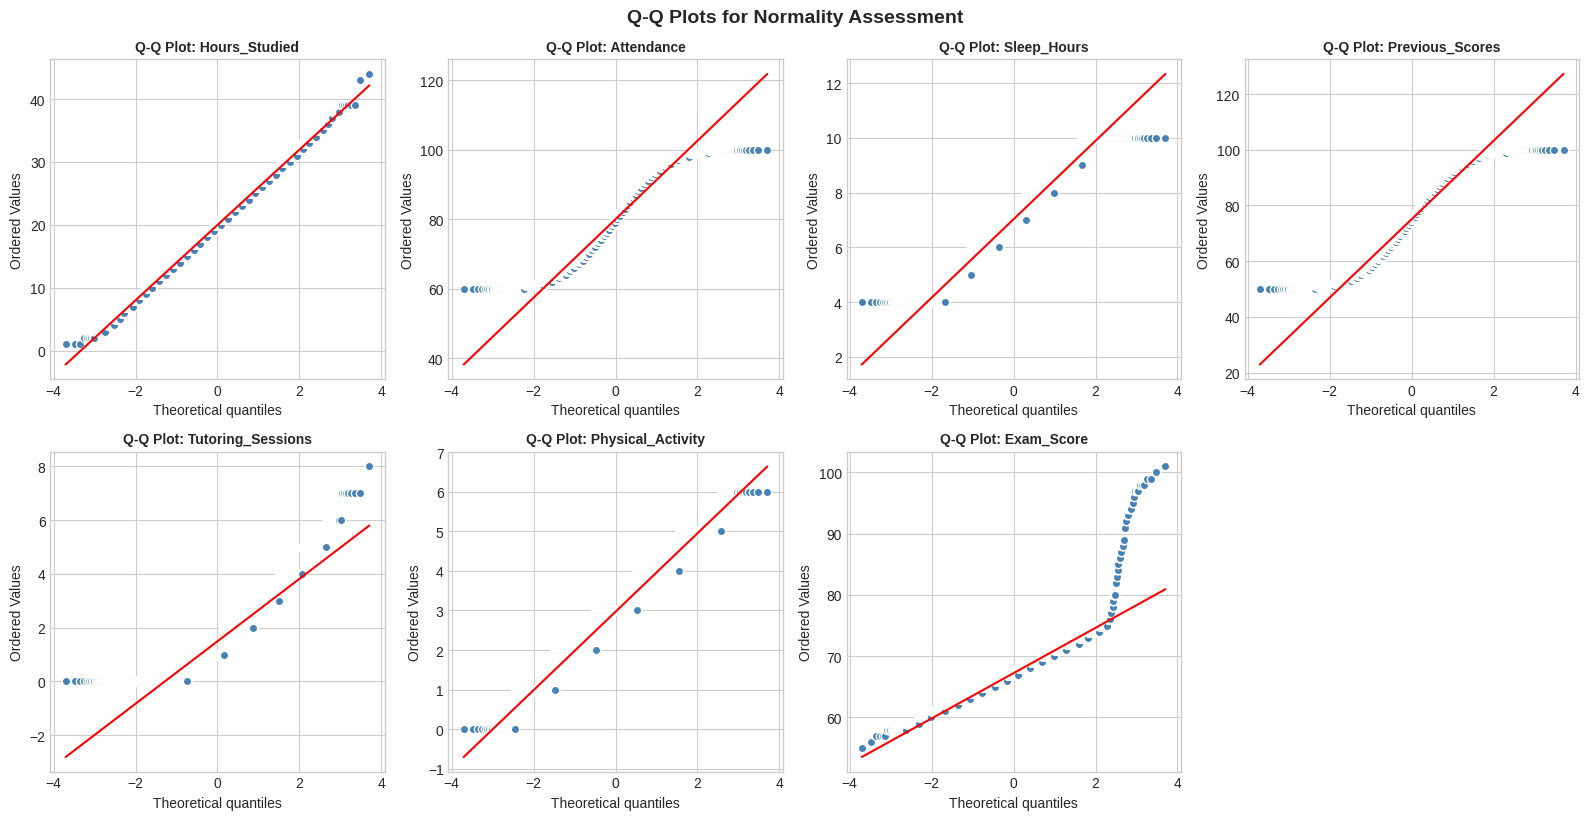


Exam Score Skewness: 1.645
Exam Score Kurtosis: 10.575


In [ ]:
# Q-Q Plots
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, col in enumerate(num_cols):
    if idx < len(axes):
        ax = axes[idx]
        stats.probplot(df_imputed[col], dist="norm", plot=ax)
        ax.set_title(f'Q-Q Plot: {col}', fontsize=10, fontweight='bold')
        ax.get_lines()[0].set_markerfacecolor('steelblue')
        ax.get_lines()[0].set_markeredgecolor('white')

for idx in range(len(num_cols), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.suptitle('Q-Q Plots for Normality Assessment', y=1.02, fontsize=14, fontweight='bold')
plt.show()

print(f"\nExam Score Skewness: {df_imputed['Exam_Score'].skew():.3f}")
print(f"Exam Score Kurtosis: {df_imputed['Exam_Score'].kurtosis():.3f}")

## 3.2 Correlation Analysis

We examine correlations between numerical variables and the target.

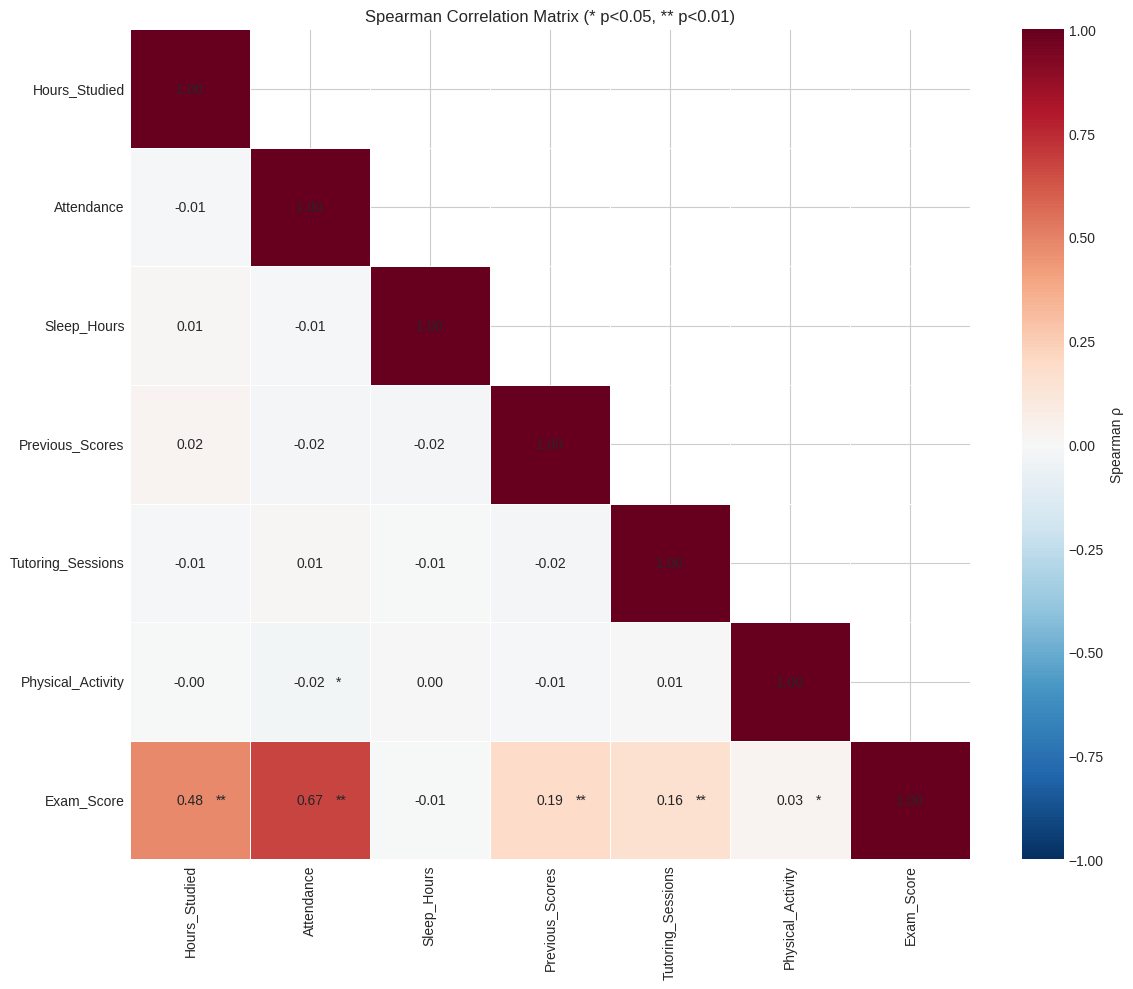

In [ ]:
numerical_cols = df_imputed.select_dtypes(include=[np.number]).columns.tolist()

corr = pd.DataFrame(np.eye(len(numerical_cols)), index=numerical_cols, columns=numerical_cols)
pvals = pd.DataFrame(np.zeros((len(numerical_cols), len(numerical_cols))), index=numerical_cols, columns=numerical_cols)

for i in range(len(numerical_cols)):
    for j in range(i + 1):
        c1, c2 = numerical_cols[i], numerical_cols[j]
        rho, p = spearmanr(df_imputed[c1], df_imputed[c2], nan_policy="omit")
        corr.iat[i, j] = rho
        corr.iat[j, i] = rho
        pvals.iat[i, j] = p
        pvals.iat[j, i] = p

def sig_star(p):
    if p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    return ""

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(12, 10))
ax = sns.heatmap(
    corr,
    mask=mask,
    vmin=-1, vmax=1,
    annot=False,
    cmap="RdBu_r",
    linewidths=.5,
    cbar_kws={"label": "Spearman ρ"}
)

n = len(numerical_cols)
for i in range(n):
    for j in range(n):
        if mask[i, j]:
            continue

        val = corr.iat[i, j]
        p = pvals.iat[i, j]
        star = "" if i == j else sig_star(p)


        ax.text(j + 0.5, i + 0.5, f"{val:.2f}", ha="center", va="center")


        if star:
            ax.text(j + 0.5 + 0.22, i + 0.5, star, ha="left", va="center", fontsize=10)

plt.title("Spearman Correlation Matrix (* p<0.05, ** p<0.01)")
plt.tight_layout()
plt.show()


## 3.3 Categorical Variable Analysis

Examining how categorical variables relate to exam scores.

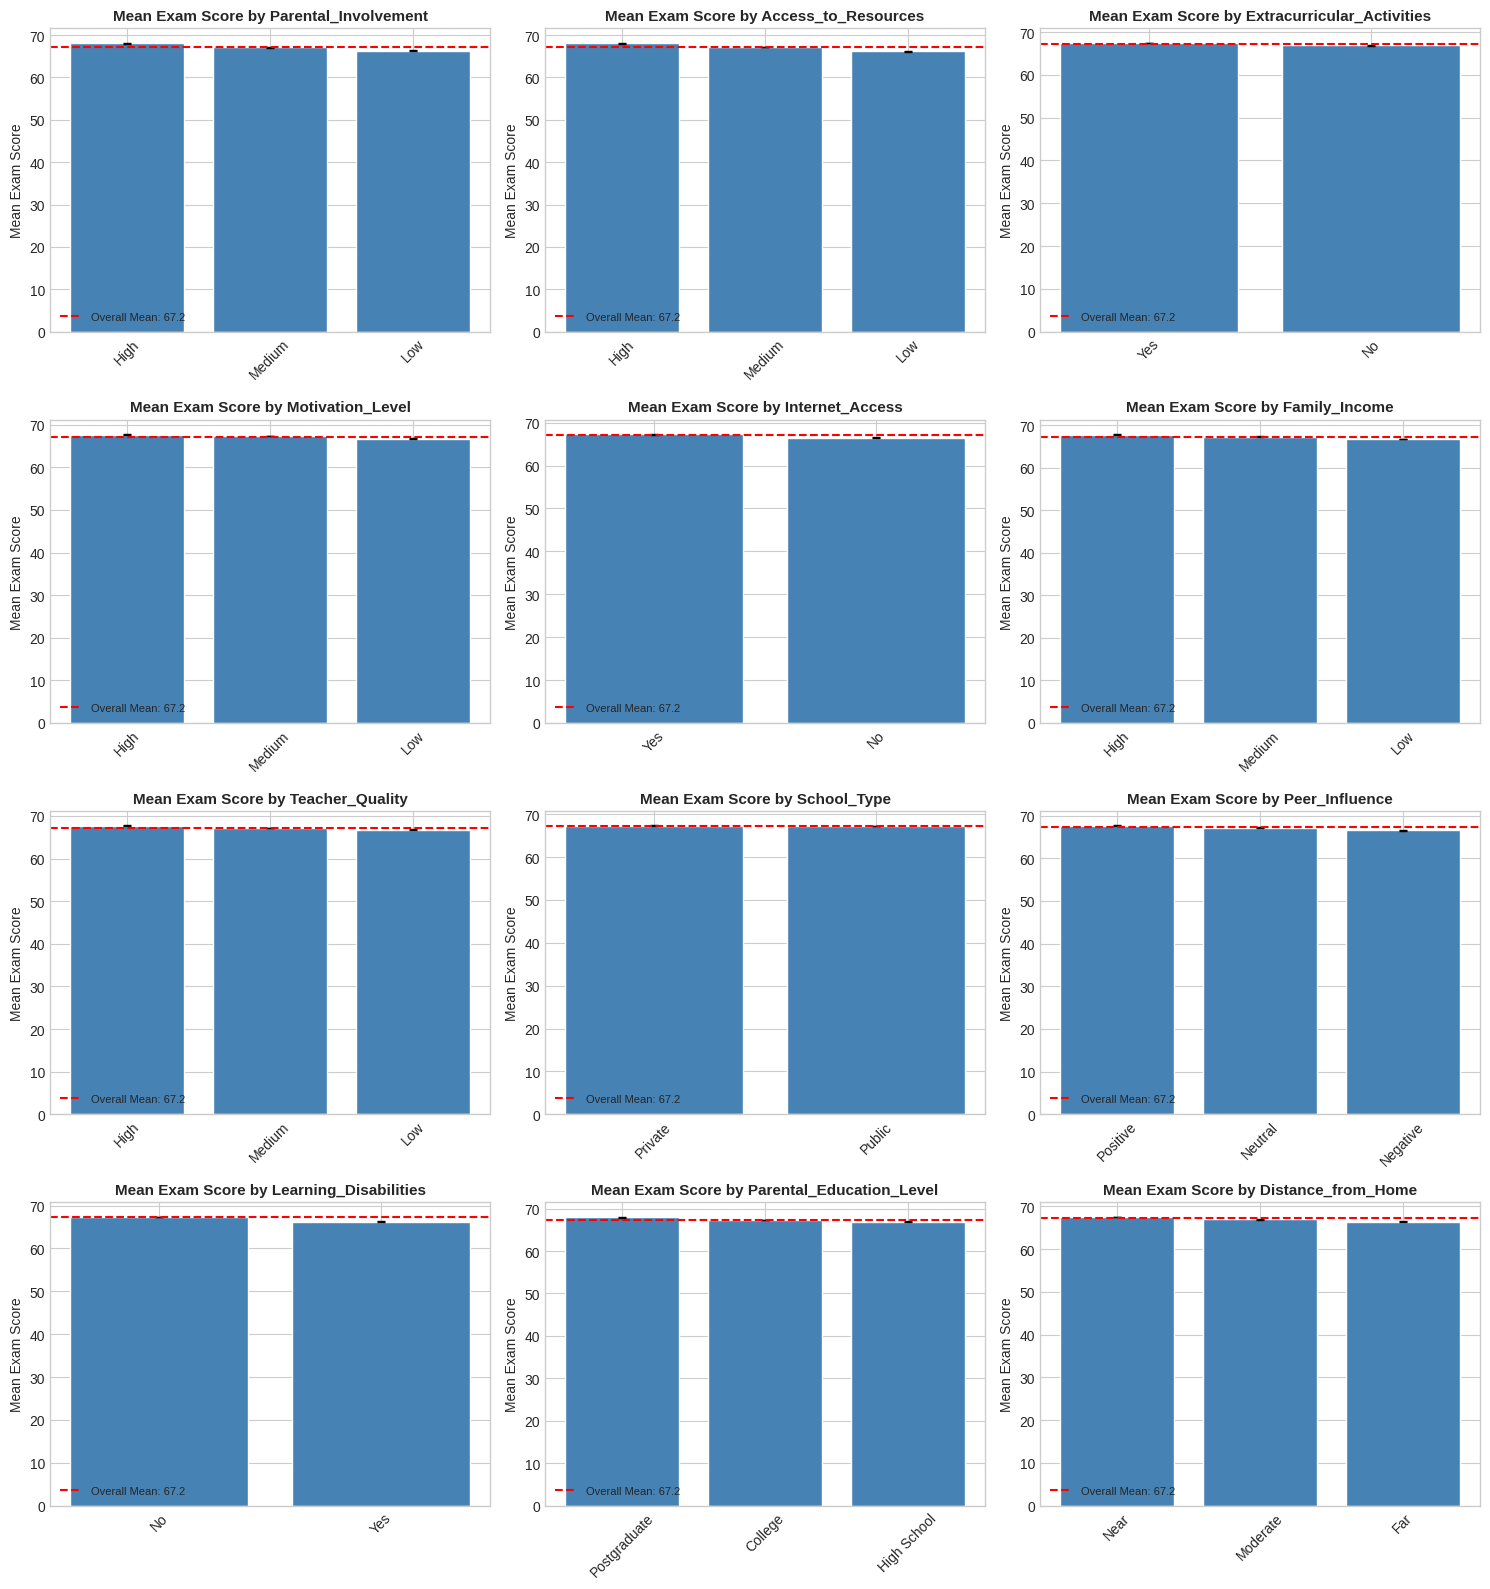

In [ ]:
# Mean exam scores by categorical variables
categorical_cols = df_imputed.select_dtypes(include='object').columns

fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.flatten()

for idx, col in enumerate(categorical_cols):
    if idx < len(axes):
        ax = axes[idx]

        # Calculate mean and std by category
        grouped = df_imputed.groupby(col)['Exam_Score'].agg(['mean', 'std', 'count']).sort_values('mean', ascending=False)

        bars = ax.bar(grouped.index, grouped['mean'],
                     yerr=grouped['std']/np.sqrt(grouped['count']),  # Standard error
                     color='steelblue', edgecolor='white', capsize=3)

        ax.axhline(df_imputed['Exam_Score'].mean(), color='red', linestyle='--',
                   label=f'Overall Mean: {df_imputed["Exam_Score"].mean():.1f}')
        ax.set_title(f'Mean Exam Score by {col}', fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', rotation=45)
        ax.legend(fontsize=8)
        ax.set_ylabel('Mean Exam Score')

for idx in range(len(categorical_cols), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

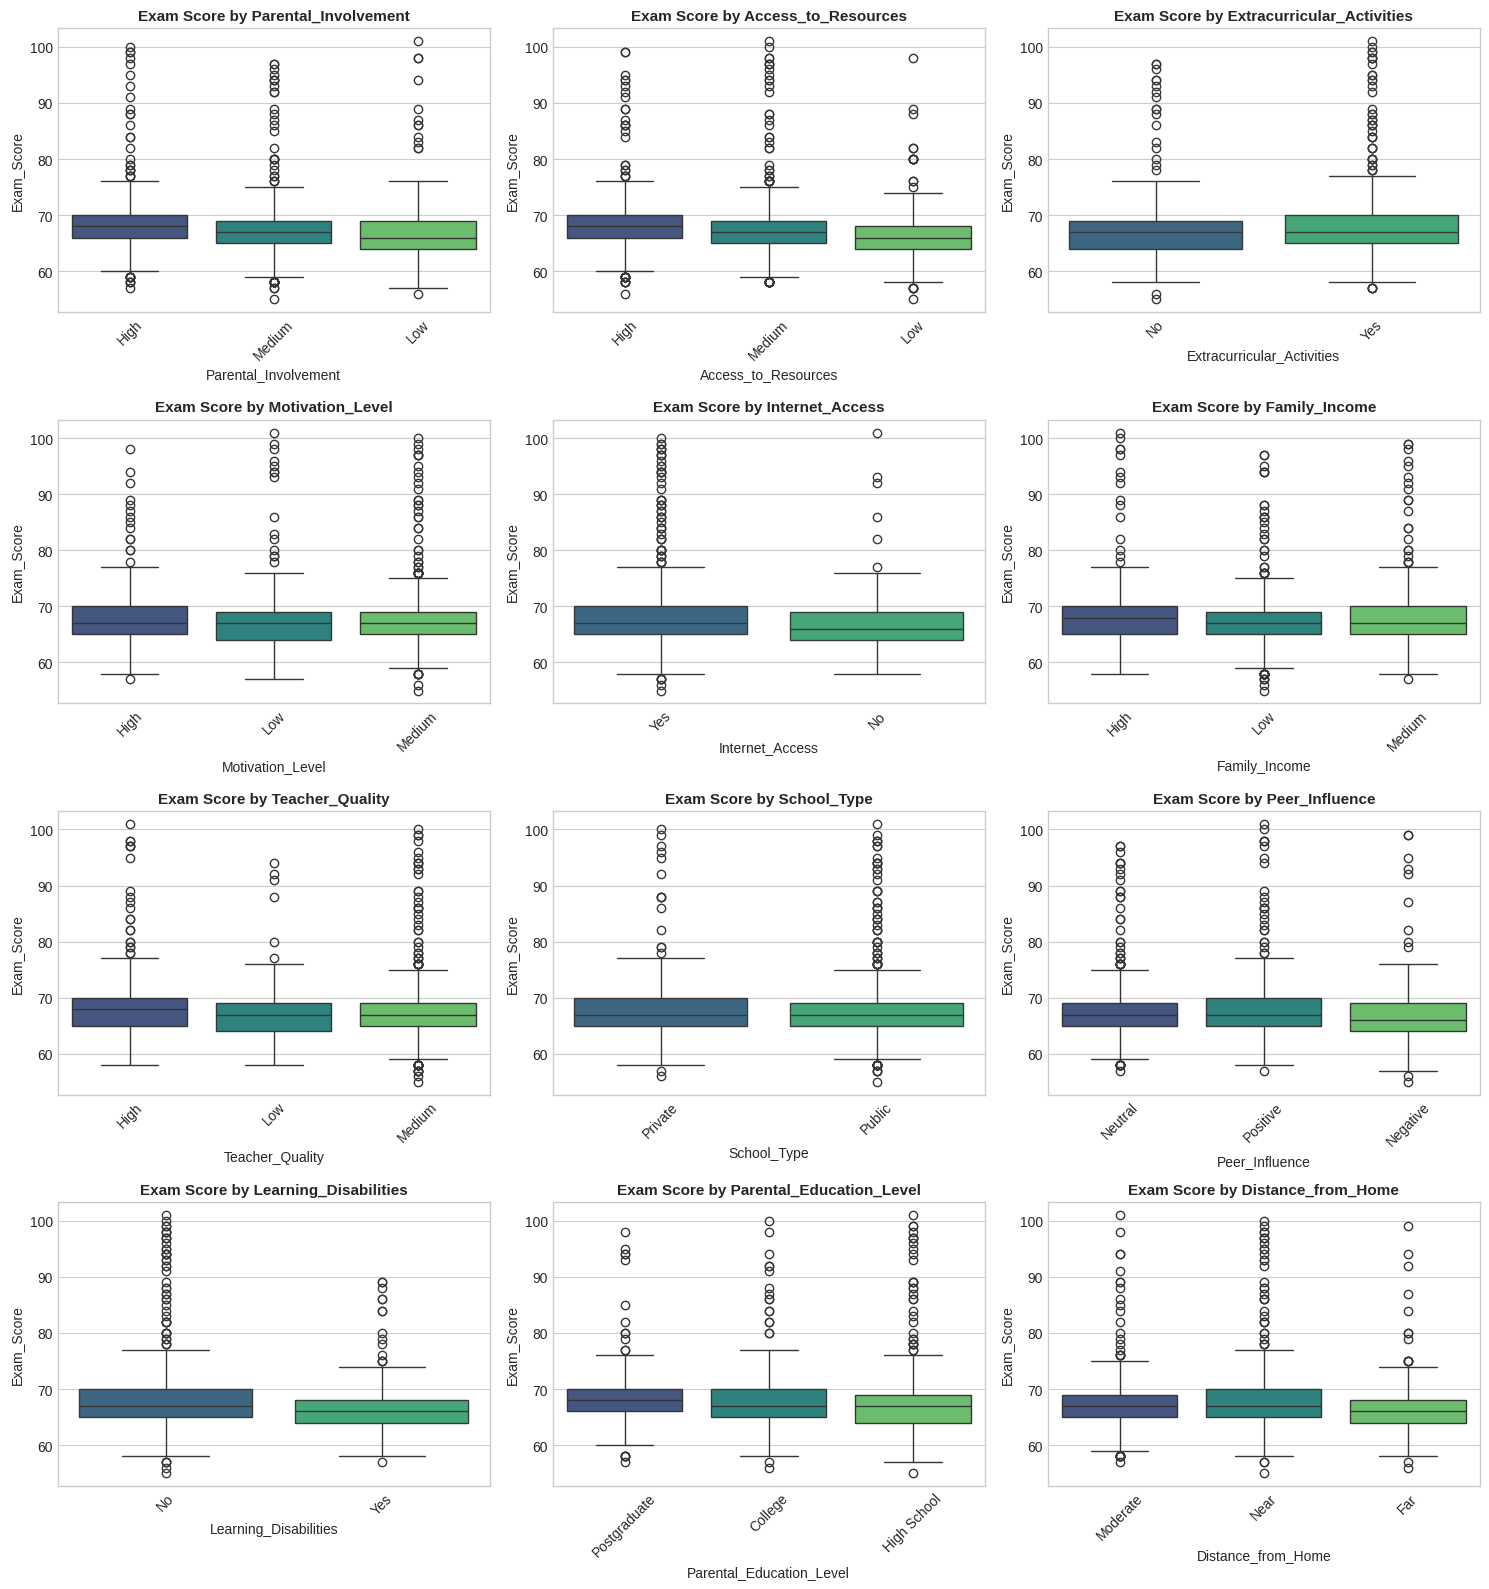

In [ ]:
# Box plots showing distribution across categories
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.flatten()

for idx, col in enumerate(categorical_cols):
    if idx < len(axes):
        ax = axes[idx]
        order = df_imputed.groupby(col)['Exam_Score'].median().sort_values(ascending=False).index
        sns.boxplot(data=df_imputed, x=col, y='Exam_Score', order=order,
                    palette='viridis', ax=ax)
        ax.set_title(f'Exam Score by {col}', fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', rotation=45)

for idx in range(len(categorical_cols), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

## 3.4 Statistical Tests

Using non-parametric tests (Mann-Whitney U / Kruskal-Wallis) to assess differences in exam scores across categorical groups.

In [ ]:
target = "Exam_Score"

continuous_vars = [
    "Hours_Studied",
    "Attendance",
    "Sleep_Hours",
    "Previous_Scores",
    "Tutoring_Sessions",
    "Physical_Activity",
    "Exam_Score",
]

exclude_vars = {"Performance_Level", "Exam_Level"}

def p_star(p):
    if pd.isna(p):
        return ""
    return "**" if p < 0.01 else ("*" if p < 0.05 else "")

def fmt_p(p):
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "<.001"
    s = f"{p:.3f}"
    return s[1:] if s.startswith("0") else s

def eps_sq(H, k, n):
    if pd.isna(H) or n <= k:
        return np.nan
    e = (H - k + 1) / (n - k)
    return max(0.0, float(e))

def rbc_from_u(U, n1, n2):
    if n1 == 0 or n2 == 0:
        return np.nan
    return (2 * U) / (n1 * n2) - 1

df2 = df.copy()
y = pd.to_numeric(df2[target], errors="coerce")

cat_cols = [c for c in df2.columns if c not in continuous_vars and c not in exclude_vars]

mw_rows = []
kw_rows = []

for cname in cat_cols:
    tmp = pd.DataFrame({"c": df2[cname], "y": y}).dropna()
    levels = tmp["c"].unique().tolist()
    k = len(levels)
    if k < 2:
        continue
    groups = [tmp.loc[tmp["c"] == lv, "y"].values for lv in levels]
    if sum(len(g) for g in groups) < 3 or any(len(g) == 0 for g in groups):
        continue

    if k == 2:
        a, b = groups[0], groups[1]
        U, p = mannwhitneyu(a, b, alternative="two-sided", method="auto")
        eff = rbc_from_u(U, len(a), len(b))
        mw_rows.append({
            "Variable": cname,
            "U": float(U),
            "p_raw": float(p),
            "Effect size (r_rb)": float(eff),
            "Effect_sort": abs(float(eff)),
        })
    else:
        H, p = kruskal(*groups)
        eff = eps_sq(H, k, int(tmp.shape[0]))
        kw_rows.append({
            "Variable": cname,
            "H": float(H),
            "p_raw": float(p),
            "Effect size (ε²)": float(eff),
            "Effect_sort": abs(float(eff)),
        })

mw_table = pd.DataFrame(mw_rows)
if not mw_table.empty:
    mw_table["SigRank"] = mw_table["p_raw"].apply(lambda x: 2 if x < 0.01 else (1 if x < 0.05 else 0))
    mw_table["p"] = mw_table["p_raw"].apply(fmt_p) + mw_table["p_raw"].apply(p_star)
    mw_table = mw_table.sort_values(["SigRank", "Effect_sort", "p_raw"], ascending=[False, False, True])
    mw_table["U"] = mw_table["U"].round(3)
    mw_table["Effect size (r_rb)"] = mw_table["Effect size (r_rb)"].round(3)
    mw_table = mw_table[["Variable", "U", "p", "Effect size (r_rb)"]]

kw_table = pd.DataFrame(kw_rows)
if not kw_table.empty:
    kw_table["SigRank"] = kw_table["p_raw"].apply(lambda x: 2 if x < 0.01 else (1 if x < 0.05 else 0))
    kw_table["p"] = kw_table["p_raw"].apply(fmt_p) + kw_table["p_raw"].apply(p_star)
    kw_table = kw_table.sort_values(["SigRank", "Effect_sort", "p_raw"], ascending=[False, False, True])
    kw_table["H"] = kw_table["H"].round(3)
    kw_table["Effect size (ε²)"] = kw_table["Effect size (ε²)"].round(3)
    kw_table = kw_table[["Variable", "H", "p", "Effect size (ε²)"]]

def show_table(title, df_table):
    display(HTML(f"<h3 style='margin: 8px 0 6px 0;'>{title}</h3>"))
    sty = (
        df_table.style
        .hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    )
    display(sty)

show_table("Mann–Whitney U results for categorical predictors of Exam_Score", mw_table)
show_table("Kruskal–Wallis results for categorical predictors of Exam_Score", kw_table)


Variable,U,p,Effect size (r_rb)
Learning_Disabilities,2427542.000000,<.001**,0.182000
Internet_Access,1730783.500000,<.001**,0.136000
Extracurricular_Activities,4860705.500000,<.001**,-0.075000
School_Type,4552099.500000,.349,-0.014000
Gender,5372067.500000,.548,0.009000


Variable,H,p,Effect size (ε²)
Access_to_Resources,231.678000,<.001**,0.035000
Parental_Involvement,195.924000,<.001**,0.029000
Parental_Education_Level,93.045000,<.001**,0.014000
Peer_Influence,84.991000,<.001**,0.013000
Distance_from_Home,70.075000,<.001**,0.010000
Family_Income,63.800000,<.001**,0.009000
Motivation_Level,59.085000,<.001**,0.009000
Teacher_Quality,44.077000,<.001**,0.006000


# 4. Data Modeling

In this section, we build and evaluate multiple regression models to predict student exam scores.

## 4.1 Data Preparation for Modeling

1.   Defined target variable: Exam_Score
2.   Features are classified to numerical and categorical
3. Pipeline approach was used to standardised numeric features and encode categorical features
4. Dataset was spilt into 70% training and 30% testing data


In [ ]:
# Prepare features and target
X = df_imputed.drop("Exam_Score", axis=1)
y = df_imputed["Exam_Score"]

# Identify feature types
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print(f"Target Variable: Exam_Score")
print(f"Numeric Features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical Features ({len(categorical_features)}): {categorical_features}")

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE
)

print(f"\nTraining set size: {len(X_train)} samples")
print(f"Test set size: {len(X_test)} samples")

Target Variable: Exam_Score
Numeric Features (6): ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
Categorical Features (13): ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

Training set size: 4624 samples
Test set size: 1983 samples


## 4.2 Baseline Model Comparison


1.   Five baseline models was used to train and test data: Linear Regression, Ridge, Lasso, Random Forest, and Gradient Boosting.
2.   Model performance was evaluated using standard metrics (R2, MSE and RMSE)
3. Bar chart was created to visually compare the result



In [ ]:
# Define baseline models
baseline_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0, random_state=RANDOM_STATE),
    "Lasso Regression": Lasso(alpha=0.01, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE)
}

# Train and evaluate baseline models
baseline_results = {}
trained_pipelines = {}

print("Training Baseline Models...")
print("-" * 70)

for name, model in baseline_models.items():
    pipe = Pipeline([
        ('preprocess', preprocessor),
        ('model', model)
    ])

    # Train
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe

    # Predict
    y_pred = pipe.predict(X_test)

    # Evaluate
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    baseline_results[name] = {"R²": r2, "RMSE": rmse, "MAE": mae}
    print(f"{name:<25} | R²: {r2:.4f} | RMSE: {rmse:.4f} | MAE: {mae:.4f}")

baseline_df = pd.DataFrame(baseline_results).T.round(4)
baseline_df = baseline_df.sort_values('R²', ascending=False)
display(baseline_df)

Training Baseline Models...
----------------------------------------------------------------------
Linear Regression         | R²: 0.7735 | RMSE: 1.7642 | MAE: 0.4571
Ridge Regression          | R²: 0.7735 | RMSE: 1.7642 | MAE: 0.4570
Lasso Regression          | R²: 0.7743 | RMSE: 1.7610 | MAE: 0.4598
Random Forest             | R²: 0.6740 | RMSE: 2.1163 | MAE: 1.1145
Gradient Boosting         | R²: 0.7359 | RMSE: 1.9049 | MAE: 0.7985


,R²,RMSE,MAE
Lasso Regression,0.7743,1.7610,0.4598
Linear Regression,0.7735,1.7642,0.4571
Ridge Regression,0.7735,1.7642,0.4570
Gradient Boosting,0.7359,1.9049,0.7985
Random Forest,0.6740,2.1163,1.1145


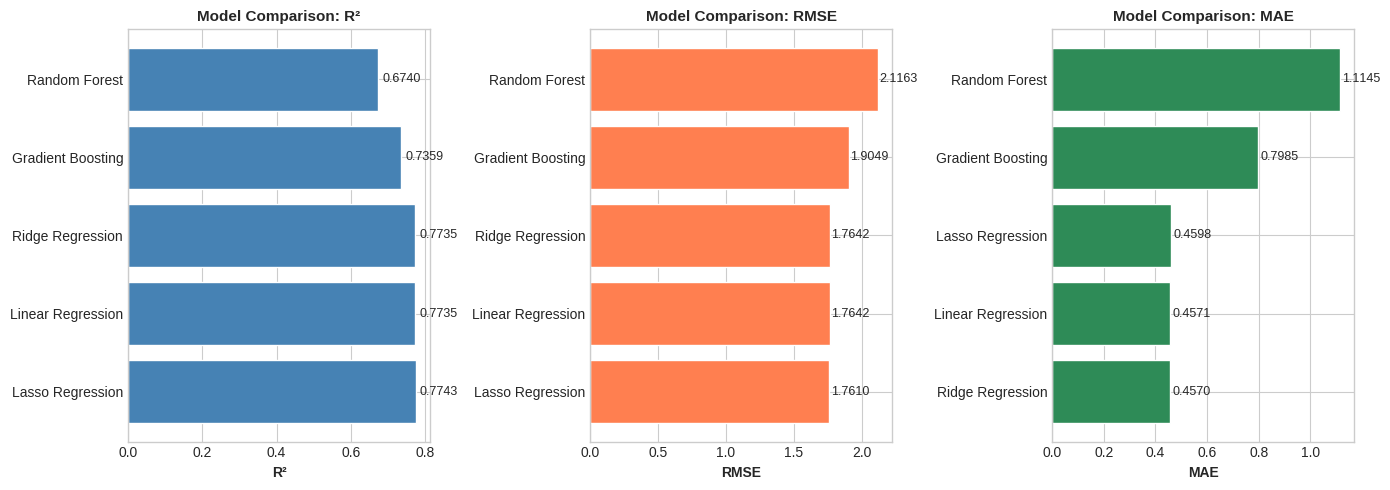


Best Baseline Model: Lasso Regression (R² = 0.7743)


In [ ]:
# Visualize baseline model comparison
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

metrics = ['R²', 'RMSE', 'MAE']
colors = ['steelblue', 'coral', 'seagreen']

for idx, metric in enumerate(metrics):
    ax = axes[idx]
    values = baseline_df[metric].sort_values(ascending=(metric != 'R²'))
    bars = ax.barh(values.index, values.values, color=colors[idx], edgecolor='white')
    ax.set_xlabel(metric, fontweight='bold')
    ax.set_title(f'Model Comparison: {metric}', fontsize=11, fontweight='bold')

    # Add value labels
    for bar, val in zip(bars, values.values):
        ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

best_baseline = baseline_df['R²'].idxmax()
print(f"\nBest Baseline Model: {best_baseline} (R² = {baseline_df.loc[best_baseline, 'R²']:.4f})")

## 4.3 10-fold Cross-Validation

To ensure robustness, 10-fold cross-validation was applied.

*   Reduces dependency on a single train-test split
*   Provides a more reliable estimate of model performance



In [ ]:
# Cross-validation for robust evaluation
print("10-Fold Cross-Validation Results:")
print("-" * 70)

cv_results = {}

for name, model in baseline_models.items():
    pipe = Pipeline([
        ('preprocess', preprocessor),
        ('model', model)
    ])

    scores = cross_val_score(pipe, X, y, cv=10, scoring='r2', n_jobs=-1)
    cv_results[name] = {
        'Mean R²': scores.mean(),
        'Std R²': scores.std(),
        'Min R²': scores.min(),
        'Max R²': scores.max()
    }
    print(f"{name:<25} | Mean R²: {scores.mean():.4f} ± {scores.std():.4f}")

cv_df = pd.DataFrame(cv_results).T.round(4)
display(cv_df.sort_values('Mean R²', ascending=False))

10-Fold Cross-Validation Results:
----------------------------------------------------------------------
Linear Regression         | Mean R²: 0.7326 ± 0.1052
Ridge Regression          | Mean R²: 0.7326 ± 0.1052
Lasso Regression          | Mean R²: 0.7322 ± 0.1050
Random Forest             | Mean R²: 0.6465 ± 0.0907
Gradient Boosting         | Mean R²: 0.6992 ± 0.0992


,Mean R²,Std R²,Min R²,Max R²
Linear Regression,0.7326,0.1052,0.6038,0.9861
Ridge Regression,0.7326,0.1052,0.6038,0.9861
Lasso Regression,0.7322,0.1050,0.6034,0.9852
Gradient Boosting,0.6992,0.0992,0.5707,0.9301
Random Forest,0.6465,0.0907,0.5261,0.8594


## 4.4 Hyperparameter Tuning - All Models

We will tune hyperparameters for using GridSearchCV:
1. Ridge Regression
2. Lasso Regression  
3. ElasticNet
4. Random Forest
5. Gradient Boosting

In [ ]:
# Additional imports for hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import ElasticNet
from sklearn.inspection import permutation_importance
from time import time

print("Additional imports loaded!")

Additional imports loaded!


In [ ]:
# Define hyperparameter search spaces

# Ridge Regression
ridge_params = {
    'model__alpha': [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0]
}

# Lasso Regression
lasso_params = {
    'model__alpha': [0.0001, 0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]
}

# ElasticNet
elasticnet_params = {
    'model__alpha': [0.001, 0.01, 0.1, 0.5, 1.0, 5.0],
    'model__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
}

# Random Forest
rf_params = {
    'model__n_estimators': [50, 100, 200, 300],
    'model__max_depth': [None, 10, 20, 30, 50],
    'model__min_samples_split': [2, 5, 10, 15],
    'model__min_samples_leaf': [1, 2, 4, 8],
    'model__max_features': ['sqrt', 'log2', 0.5, 0.8, None]
}

# Gradient Boosting
gb_params = {
    'model__n_estimators': [50, 100, 200, 300],
    'model__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'model__max_depth': [3, 5, 7, 10],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__subsample': [0.7, 0.8, 0.9, 1.0]
}

print("Hyperparameter grids defined!")

Hyperparameter grids defined!


In [ ]:
# Define tuning configurations
tuning_configs = {
    "Ridge (Tuned)": {
        "model": Ridge(random_state=RANDOM_STATE),
        "params": ridge_params,
        "search_type": "grid"
    },
    "Lasso (Tuned)": {
        "model": Lasso(random_state=RANDOM_STATE, max_iter=10000),
        "params": lasso_params,
        "search_type": "grid"
    },
    "ElasticNet (Tuned)": {
        "model": ElasticNet(random_state=RANDOM_STATE, max_iter=10000),
        "params": elasticnet_params,
        "search_type": "grid"
    },
    "Random Forest (Tuned)": {
        "model": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
        "params": rf_params,
        "search_type": "random",
        "n_iter": 50
    },
    "Gradient Boosting (Tuned)": {
        "model": GradientBoostingRegressor(random_state=RANDOM_STATE),
        "params": gb_params,
        "search_type": "random",
        "n_iter": 50
    }
}

print(f"Configured {len(tuning_configs)} models for tuning")

Configured 5 models for tuning


In [ ]:
# Perform hyperparameter tuning
print("Starting Hyperparameter Tuning...")
print("This may take several minutes. Please wait...\n")

print(f"{'Model':<30} | {'Best CV R²':>12} | {'Test R²':>10} | {'RMSE':>8} | {'MAE':>8} | {'Time':>8}")
print("-" * 100)

tuned_results = {}
tuned_pipelines = {}
best_params_all = {}

for name, config in tuning_configs.items():
    start_time = time()

    pipe = Pipeline([
        ('preprocess', preprocessor),
        ('model', config["model"])
    ])

    if config["search_type"] == "grid":
        search = GridSearchCV(
            pipe, config["params"], cv=5, scoring='r2',
            n_jobs=-1, verbose=0
        )
    else:
        search = RandomizedSearchCV(
            pipe, config["params"], n_iter=config.get("n_iter", 30),
            cv=5, scoring='r2', n_jobs=-1, verbose=0, random_state=RANDOM_STATE
        )

    search.fit(X_train, y_train)

    # Store results
    tuned_pipelines[name] = search.best_estimator_
    best_params_all[name] = search.best_params_

    # Evaluate
    y_pred = search.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    elapsed = time() - start_time

    tuned_results[name] = {
        "Best CV R²": search.best_score_,
        "Test R²": r2,
        "RMSE": rmse,
        "MAE": mae,
        "Time": elapsed
    }

    print(f"{name:<30} | {search.best_score_:>12.4f} | {r2:>10.4f} | {rmse:>8.4f} | {mae:>8.4f} | {elapsed:>7.1f}s")

print("=" * 100)
print("\n Hyperparameter tuning complete!")

Starting Hyperparameter Tuning...
This may take several minutes. Please wait...

Model                          |   Best CV R² |    Test R² |     RMSE |      MAE |     Time
----------------------------------------------------------------------------------------------------
Ridge (Tuned)                  |       0.7200 |     0.7736 |   1.7635 |   0.4564 |     4.4s
Lasso (Tuned)                  |       0.7200 |     0.7736 |   1.7637 |   0.4564 |     5.1s
ElasticNet (Tuned)             |       0.7200 |     0.7736 |   1.7637 |   0.4564 |    11.4s
Random Forest (Tuned)          |       0.6399 |     0.6993 |   2.0328 |   1.0338 |   363.0s
Gradient Boosting (Tuned)      |       0.6998 |     0.7516 |   1.8474 |   0.6699 |   490.9s

 Hyperparameter tuning complete!


In [ ]:
# Display tuned results as DataFrame
tuned_df = pd.DataFrame(tuned_results).T.round(4)
tuned_df = tuned_df.sort_values('Test R²', ascending=False)
print("\nTuned Model Results (Sorted by Test R²):")
display(tuned_df)


Tuned Model Results (Sorted by Test R²):


,Best CV R²,Test R²,RMSE,MAE,Time
Ridge (Tuned),0.7200,0.7736,1.7635,0.4564,4.3568
Lasso (Tuned),0.7200,0.7736,1.7637,0.4564,5.1222
ElasticNet (Tuned),0.7200,0.7736,1.7637,0.4564,11.4162
Gradient Boosting (Tuned),0.6998,0.7516,1.8474,0.6699,490.9034
Random Forest (Tuned),0.6399,0.6993,2.0328,1.0338,362.9671


## 4.5 Complete Model Comparison

Compare all baseline models vs tuned models to see improvements.

In [ ]:
# Combine baseline and tuned results
all_results = {}

# Add baseline results
for name, results in baseline_results.items():
    all_results[f"{name} (Baseline)"] = {
        "R²": results["R²"],
        "RMSE": results["RMSE"],
        "MAE": results["MAE"],
        "Type": "Baseline"
    }

# Add tuned results
for name, results in tuned_results.items():
    all_results[name] = {
        "R²": results["Test R²"],
        "RMSE": results["RMSE"],
        "MAE": results["MAE"],
        "Type": "Tuned"
    }

# Create comparison DataFrame
comparison_df = pd.DataFrame(all_results).T.round(4)
comparison_df = comparison_df.sort_values('R²', ascending=False)


print("COMPLETE MODEL COMPARISON (All Models Ranked by R²)")
print("-" * 80)
display(comparison_df)

COMPLETE MODEL COMPARISON (All Models Ranked by R²)
--------------------------------------------------------------------------------


,R²,RMSE,MAE,Type
Lasso Regression (Baseline),0.774287,1.761048,0.459825,Baseline
Ridge (Tuned),0.773648,1.76354,0.4564,Tuned
Lasso (Tuned),0.773619,1.763653,0.456374,Tuned
ElasticNet (Tuned),0.773612,1.763678,0.4564,Tuned
Ridge Regression (Baseline),0.773486,1.764169,0.456984,Baseline
Linear Regression (Baseline),0.773467,1.764246,0.457069,Baseline
Gradient Boosting (Tuned),0.751599,1.847438,0.669862,Tuned
Gradient Boosting (Baseline),0.7359,1.904921,0.798539,Baseline
Random Forest (Tuned),0.69925,2.032804,1.033756,Tuned
Random Forest (Baseline),0.674026,2.116335,1.114483,Baseline


## 4.6 Best Model Selection

Choosing the best model from all the model both baseline and tuned ones

In [ ]:
# Identify the best model
best_model_name = comparison_df['R²'].idxmax()
best_r2 = comparison_df.loc[best_model_name, 'R²']
best_rmse = comparison_df.loc[best_model_name, 'RMSE']
best_mae = comparison_df.loc[best_model_name, 'MAE']


print(f"\n BEST MODEL: {best_model_name}")
print(f"       a)R² Score: {best_r2:.4f} ({best_r2*100:.1f}% variance explained)")
print(f"       b)RMSE: {best_rmse:.4f}")
print(f"       c)MAE: {best_mae:.4f}")


# Get the best pipeline
if best_model_name in tuned_pipelines:
    best_pipeline = tuned_pipelines[best_model_name]
else:
    base_name = best_model_name.replace(" (Baseline)", "")
    best_pipeline = trained_pipelines.get(base_name)


 BEST MODEL: Lasso Regression (Baseline)
       a)R² Score: 0.7743 (77.4% variance explained)
       b)RMSE: 1.7610
       c)MAE: 0.4598


In [ ]:
# Print best hyperparameters for each model

print("BEST HYPERPARAMETERS FOR TUNED MODELS")
print("-" * 80)

for name, params in best_params_all.items():
    print(f"\n {name}:")
    for param, value in params.items():
        param_name = param.replace('model__', '')
        print(f"   • {param_name}: {value}")

BEST HYPERPARAMETERS FOR TUNED MODELS
--------------------------------------------------------------------------------

 Ridge (Tuned):
   • alpha: 10.0

 Lasso (Tuned):
   • alpha: 0.001

 ElasticNet (Tuned):
   • alpha: 0.001
   • l1_ratio: 0.9

 Random Forest (Tuned):
   • n_estimators: 300
   • min_samples_split: 5
   • min_samples_leaf: 1
   • max_features: 0.5
   • max_depth: None

 Gradient Boosting (Tuned):
   • subsample: 0.7
   • n_estimators: 300
   • min_samples_split: 5
   • min_samples_leaf: 4
   • max_depth: 3
   • learning_rate: 0.05


# 5 Conclusion

In conclusion, the analytical results provide clear value for the EdTech tuition centre’s business objective by enabling earlier identification of students who are likely to underperform below average. Insights from both EDA and modelling highlight the key behavioural drivers for performance, allowing the educators to prioritise resources to students who are at risk of underperforming. The personalised strategies provided by the web-based application could be utilised by parents, teachers and students to identify key areas for improvements. The innovative  application reflects EdTech's strong value towards quality education, and this could build a greater trust among parents, thus improving the concerning, constant retention rate. Collectively, these results support data-driven and decision-making, and more effective academic planning for their valued students.
